In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np

from config import get_device, WAV_INPUT_DIR, WHISPER_TRANSCRIPTS_DIR
from whisper_transcripts import get_transcript
from items import WhisperTranscript

In [4]:
list(WAV_INPUT_DIR.iterdir())

[PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch20-22.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch7-9.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch15-19.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch10-12.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch23-25.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch1-3.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch4-6.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch26-27.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/a

In [5]:
WAV = list(WAV_INPUT_DIR.iterdir())[0]
WAV

PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch20-22.wav')

### Transcribe

In [6]:
device = get_device()
device

'cuda'

In [ ]:
res = get_transcript(
    audio=str(WAV),
    model_size="large-v2",
    device=device,
    initial_prompt=None,
    fp16=False,
    language="fr",
    do_vad=False,
)

#### Load result

In [32]:
ready_files = list(WHISPER_TRANSCRIPTS_DIR.iterdir())
print(ready_files)
wav_name = ready_files[0].stem
wav_name = wav_name.split("_whisper_")[0]
print(wav_name)
res = WhisperTranscript.from_wav_path(wav_name, 'base')

[PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch1-3_whisper_base.json')]
ch1-3


<Axes: >

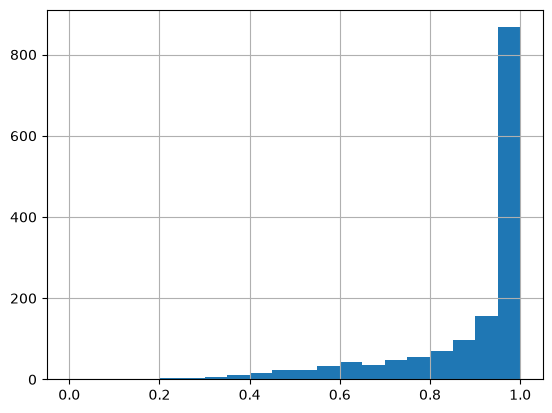

In [29]:
df = []
for s in res.whisper_result['segments']:
    for w in s['words']:
        df.append(w)
df = pd.DataFrame(df)

df.confidence.hist(bins=np.arange(0, 1.05, 0.05))

In [31]:
df

,text,start,end,confidence
0,Lorsque,3.04,3.38,0.789
1,j'avais,3.38,3.70,0.994
2,6,3.70,4.06,0.593
3,"ans,",4.06,4.30,0.996
4,j'ai,4.48,4.70,0.988
...,...,...,...,...
1485,peut,609.46,609.58,0.983
1486,pas,609.58,609.74,1.000
1487,aller,609.74,609.98,0.906
1488,bien,609.98,610.14,0.997
